In [1]:
%matplotlib inline

In [ ]:
import numpy as np 
from matplotlib import pyplot as plt
from scipy.stats import powerlaw
from scipy.stats import gaussian_kde
from scipy.stats import exponpow

from halotools.sim_manager import CachedHaloCatalog
from halotools.empirical_models import Moster13SmHm
from halotools.empirical_models import conditional_abunmatch

# Create "Observed" Dataset

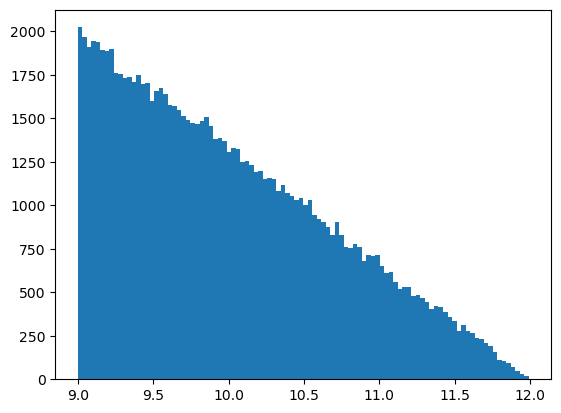

In [6]:
# generate power law distributed stellar mass

ngals_tot = int(1e5)
slope = 2
# this power law is random as far as i can tell
log_mstar = 3*(1-powerlaw.rvs(slope, size=ngals_tot)) + 9
galaxy_mstar = 10**log_mstar
fig, ax = plt.subplots(1, 1)

__=ax.hist(log_mstar, bins=100)

In [7]:
# quenching is the process by which star formation stops in a galaxy
# Model the quenched fraction vs. M* (peak stellar formation) with an exponential
log_mstar_crit = 10.5
uran = np.random.rand(ngals_tot)
is_quenched = uran < 1-np.exp(-(log_mstar/log_mstar_crit)**5)

num_quenched = np.count_nonzero(is_quenched)
num_star_forming = ngals_tot - num_quenched

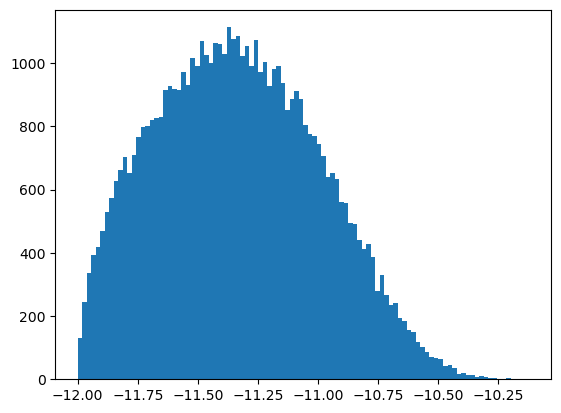

In [ ]:
# generate quenching sequence "Stellar Formation Rate" (SFR) using exponential power

b = 1.5
log_ssfr_quenched = exponpow.rvs(b, loc=-12, scale=1, size=num_quenched)
ssfr_quenched = 10**log_ssfr_quenched

fig, ax = plt.subplots(1, 1)

__=ax.hist(log_ssfr_quenched, bins=100)

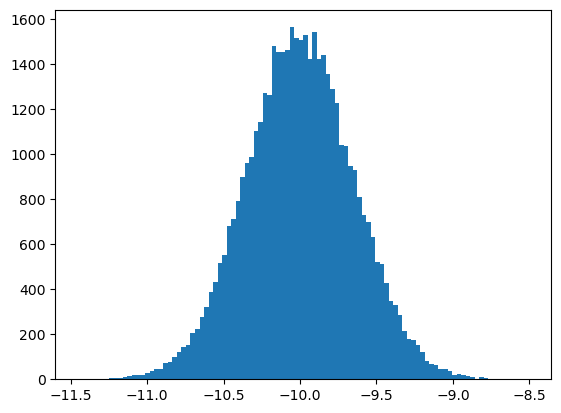

In [9]:
# generate star forming sequence star fomation rate using log-normal
log_ssfr_main_sequence = np.random.normal(loc=-10, scale=0.35, size=num_star_forming)
ssfr_star_forming = 10**log_ssfr_main_sequence

fig, ax = plt.subplots(1, 1)

__=ax.hist(log_ssfr_main_sequence, bins=100)

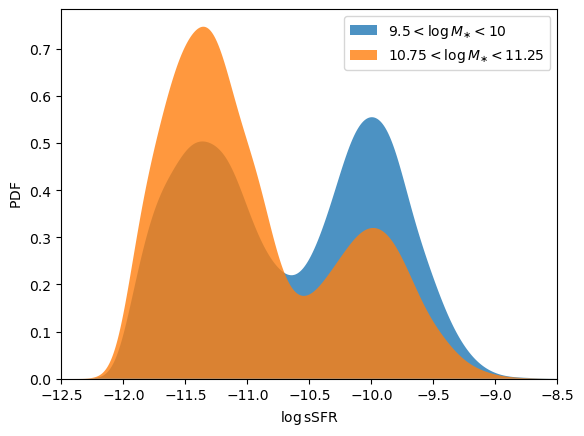

In [38]:
# build composite galaxy population
galaxy_ssfr = np.zeros_like(galaxy_mstar)
galaxy_ssfr[is_quenched] = ssfr_quenched
galaxy_ssfr[~is_quenched] = ssfr_star_forming

logsm_low, logsm_high = 9.5, 10
mask1 = (log_mstar >= logsm_low) & (log_mstar < logsm_high)

logsm_low, logsm_high = 10.75, 11.25
mask2 = (log_mstar >= logsm_low) & (log_mstar < logsm_high)

fig, ax = plt.subplots(1, 1)

kde1 = gaussian_kde(np.log10(galaxy_ssfr[mask1]))
kde2 = gaussian_kde(np.log10(galaxy_ssfr[mask2]))

x = np.linspace(-12.5, -8, 1000)
pdf1 = kde1.evaluate(x)
pdf2 = kde2.evaluate(x)

__=ax.fill(x, pdf1, alpha=0.8, label=r'$9.5 < \log M_{\ast} < 10$')
__=ax.fill(x, pdf2, alpha=0.8, label=r'$10.75 < \log M_{\ast} < 11.25$')

xlim = ax.set_xlim(-12.5, -8.5)
ylim = ax.set_ylim(ymin=0)
legend = ax.legend()

xlabel = ax.set_xlabel(r'$\log{\rm sSFR}$')
ylabel = ax.set_ylabel(r'${\rm PDF}$')

# figname = 'cam_example_complex_sfr.png'
# fig.savefig(figname, bbox_extra_artists=[xlabel, ylabel], bbox_inches='tight')

In [ ]:
# painting stellar mass onto subhalos in the Bolshoi z=0 rockstar halos simulation
halocat = CachedHaloCatalog()

model = Moster13SmHm()

halocat.halo_table['stellar_mass'] = model.mc_stellar_mass(
    prim_haloprop=halocat.halo_table['halo_mpeak'], redshift=0)

print(halocat.halo_table.keys())


['halo_vmax_firstacc', 'halo_dmvir_dt_tdyn', 'halo_macc', 'halo_scale_factor', 'halo_vmax_mpeak', 'halo_m_pe_behroozi', 'halo_xoff', 'halo_spin', 'halo_scale_factor_firstacc', 'halo_c_to_a', 'halo_mvir_firstacc', 'halo_scale_factor_last_mm', 'halo_scale_factor_mpeak', 'halo_pid', 'halo_m500c', 'halo_id', 'halo_halfmass_scale_factor', 'halo_upid', 'halo_t_by_u', 'halo_rvir', 'halo_vpeak', 'halo_dmvir_dt_100myr', 'halo_mpeak', 'halo_m_pe_diemer', 'halo_jx', 'halo_jy', 'halo_jz', 'halo_m2500c', 'halo_mvir', 'halo_voff', 'halo_axisA_z', 'halo_axisA_x', 'halo_axisA_y', 'halo_y', 'halo_b_to_a', 'halo_x', 'halo_z', 'halo_m200b', 'halo_vacc', 'halo_scale_factor_lastacc', 'halo_vmax', 'halo_m200c', 'halo_vx', 'halo_vy', 'halo_vz', 'halo_dmvir_dt_inst', 'halo_rs', 'halo_nfw_conc', 'halo_hostid', 'halo_mvir_host_halo', 'stellar_mass']


## Conditional Abundance Matching (CAM)

Goal: Assign mock galaxy sSFR values to Bolshoi DMO halos using
halo mass-accretion rate as the secondary halo proxy.

1. Match DMO halos to mock galaxies by stellar-mass rank.
2. For each halo, identify a local window of approximately 200 objects
   around the stellar-mass match.
3. Rank the halo mass-accretion rates within the halo window.
4. Rank the mock-galaxy sSFR values within the corresponding galaxy window.
5. Match the halo and galaxy secondary-property percentiles.
6. Assign the matched mock `log10(sSFR)` value to the DMO halo.

Here, sSFR is the specific star-formation rate:
sSFR = SFR / M_star.

In [ ]:
x = halocat.halo_table['stellar_mass']
y = halocat.halo_table['halo_dmvir_dt_100myr']

x2 = galaxy_mstar
y2 = np.log10(galaxy_ssfr)
nwin = 201

halocat.halo_table['log_ssfr'] = conditional_abunmatch(x, y, x2, y2, nwin)

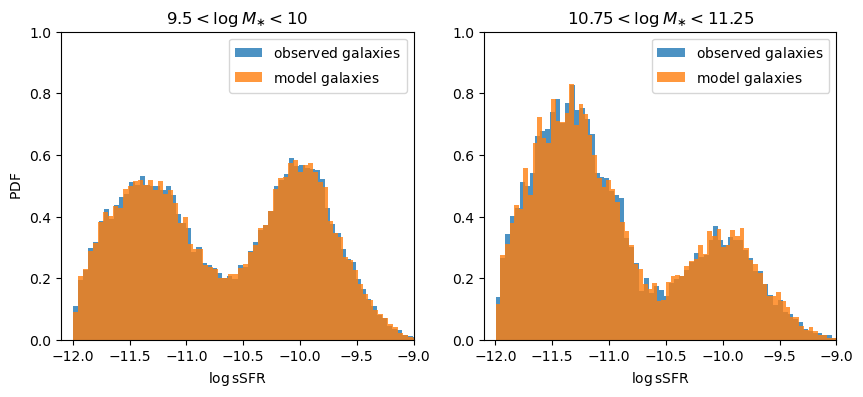

In [18]:
logsm_low, logsm_high = 9.5, 10
mask1_gals = (log_mstar >= logsm_low) & (log_mstar < logsm_high)
mask1_halos = (np.log10(halocat.halo_table['stellar_mass']) >= logsm_low)
mask1_halos *= (np.log10(halocat.halo_table['stellar_mass']) < logsm_high)

logsm_low, logsm_high = 10.75, 11.25
mask2_gals = (log_mstar >= logsm_low) & (log_mstar < logsm_high)
mask2_halos = (np.log10(halocat.halo_table['stellar_mass']) >= logsm_low)
mask2_halos *= (np.log10(halocat.halo_table['stellar_mass']) < logsm_high)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

__=ax1.hist(np.log10(galaxy_ssfr[mask1_gals]), bins=75, density = True, stacked = True, alpha=0.8, 
          label=r'${\rm observed\ galaxies}$')
__=ax1.hist(halocat.halo_table['log_ssfr'][mask1_halos], bins=75, density = True, stacked = True, alpha=0.8,
          label=r'${\rm model\ galaxies}$')
__=ax2.hist(np.log10(galaxy_ssfr[mask2_gals]), bins=75, density = True, stacked = True, alpha=0.8, 
          label=r'${\rm observed\ galaxies}$')
__=ax2.hist(halocat.halo_table['log_ssfr'][mask2_halos], bins=75, density = True, stacked = True, alpha=0.8,
          label=r'${\rm model\ galaxies}$')

legend1 = ax1.legend()
legend2 = ax2.legend()

ylim1 = ax1.set_ylim(0, 1)
xlim1 = ax1.set_xlim(-12.1, -9)
ylim2 = ax2.set_ylim(0, 1)
xlim2 = ax2.set_xlim(-12.1, -9)

xlabel1 = ax1.set_xlabel(r'$\log{\rm sSFR}$')
xlabel2 = ax2.set_xlabel(r'$\log{\rm sSFR}$')
ylabel1 = ax1.set_ylabel(r'${\rm PDF}$')
title1 = ax1.set_title(r'$9.5 < \log M_{\ast} < 10$')
title2 = ax2.set_title(r'$10.75 < \log M_{\ast} < 11.25$')

figname = 'cam_example_complex_sfr_recovery.png'
fig.savefig(figname, bbox_extra_artists=[xlabel1, ylabel1], bbox_inches='tight')

## Summary
Given halo stellar mass and halo mass-accretion rate, CAM can assign sSFR values to halos such that the sSFR distribution in a fixed stellar-mass bin matches the chosen mock galaxy distribution. This demonstrates distributional recovery, while the predictive physical relationship still requires separate validation.